In [1]:
import os, re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from PIL import Image, ImageDraw, ImageFont

Using CPU. Note: This module is much faster with a GPU.
c:\CC\Lab9\.venv\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
c:\CC\Lab9\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


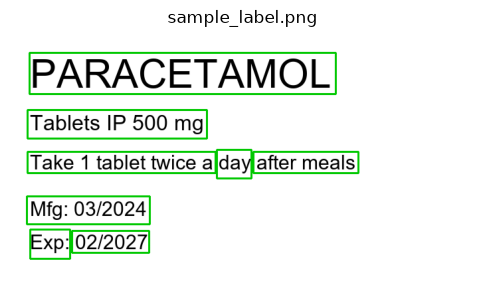

This looks like PARACETAMOL. Strength: 500 mg. Directions: Take 1 tablet twice a. I could not find an expiry date, please check the bottle. 



,file,name,dosage,mfg,expiry,usage
0,sample_label.png,PARACETAMOL,[500 mg],03/2024,None,"[Take 1 tablet twice a, after meals]"


In [2]:
import easyocr

img_dir = "medicine_images"
os.makedirs(img_dir, exist_ok=True)
paths = [os.path.join(img_dir, f) for f in os.listdir(img_dir)
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]

def get_font(size):
    for name in ["arial.ttf", "DejaVuSans.ttf"]:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            pass
    return ImageFont.load_default()



reader = easyocr.Reader(["en"], gpu=False)
SCALE = 1.5

def preprocess(img):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_CUBIC)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)

def is_expired(date_str):
    try:
        m, y = re.split(r"\s*[/\-]\s*", date_str.strip())
        y = int(y)
        y = y + 2000 if y < 100 else y
        now = datetime.now()
        return (y, int(m)) < (now.year, now.month)
    except ValueError:
        return None

def parse_label(items):
    lines = [t for _, t, _ in items]
    full = " | ".join(lines)
    # drug name is usually the biggest text on the label
    biggest = max(items, key=lambda x: abs(x[0][2][1] - x[0][0][1]))
    dose = re.findall(r"(\d+(?:\.\d+)?)\s*(mg|mcg|g|ml|iu)\b", full, flags=re.I)
    exp = re.search(r"exp\w*\.?\s*(?:date)?\s*[:\-]?\s*(\d{1,2}\s*[/\-]\s*\d{2,4})", full, flags=re.I)
    mfg = re.search(r"(?:mfg|mfd|manufactured)\w*\.?\s*(?:date)?\s*[:\-]?\s*(\d{1,2}\s*[/\-]\s*\d{2,4})", full, flags=re.I)
    usage = [l for l in lines if re.search(r"\b(take|daily|twice|once|meals|dose)\b", l, flags=re.I)]
    return {
        "name": biggest[1],
        "dosage": [f"{a} {b.lower()}" for a, b in dose],
        "mfg": mfg.group(1) if mfg else None,
        "expiry": exp.group(1) if exp else None,
        "usage": usage,
    }

def assistant_reply(info):
    msg = f"This looks like {info['name']}."
    if info["dosage"]:
        msg += f" Strength: {', '.join(info['dosage'])}."
    if info["usage"]:
        msg += f" Directions: {info['usage'][0]}."
    if info["expiry"]:
        exp = is_expired(info["expiry"])
        if exp:
            msg += f" Warning, it expired in {info['expiry']}. Do not use it."
        elif exp is False:
            msg += f" It is valid till {info['expiry']}."
    else:
        msg += " I could not find an expiry date, please check the bottle."
    return msg

summary = []
for p in paths:
    img = cv2.imread(p)
    raw = reader.readtext(preprocess(img))
    items = [r for r in raw if r[2] > 0.3]
    if not items:
        print(p, "- no text found")
        continue
    info = parse_label(items)
    for box, text, conf in items:
        pts = (np.array(box) / SCALE).astype(int)
        cv2.rectangle(img, tuple(pts[0]), tuple(pts[2]), (0, 200, 0), 2)
    plt.figure(figsize=(6, 4))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(os.path.basename(p))
    plt.show()
    print(assistant_reply(info), "\n")
    summary.append({"file": os.path.basename(p), **info})

pd.DataFrame(summary)

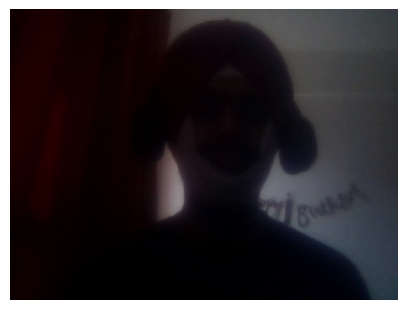

no faces detected


In [3]:
from deepface import DeepFace

face_dir = "face_images"
os.makedirs(face_dir, exist_ok=True)

use_webcam = True
if use_webcam:
    cam = cv2.VideoCapture(0)
    ok, frame = cam.read()
    cam.release()
    if ok:
        cv2.imwrite(os.path.join(face_dir, "webcam.jpg"), frame)

paths = [os.path.join(face_dir, f) for f in os.listdir(face_dir)
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]
if not paths:
    print("No images in", face_dir, "- add some or turn on the webcam")

responses = {
    "happy": "You look happy! Glad to see that, want to keep going with your task?",
    "sad": "You seem a bit down. Want to take a short break or listen to some music?",
    "angry": "You look upset. Take a deep breath, I can wait until you are ready.",
    "fear": "You seem worried. Tell me what is bothering you and I will help.",
    "surprise": "Looks like something surprised you! Do you want me to explain anything?",
    "disgust": "Something seems off. Should I change what I just showed you?",
    "neutral": "You seem calm. How can I help you today?",
}

rows = []
first_scores = None
for p in paths:
    img = cv2.imread(p)
    res = DeepFace.analyze(img, actions=["emotion"], detector_backend="opencv",
                           enforce_detection=False)
    if isinstance(res, dict):
        res = [res]
    for r in res:
        if r.get("face_confidence", 1) == 0:
            continue
        reg = r["region"]
        x, y, w, h = reg["x"], reg["y"], reg["w"], reg["h"]
        emo = r["dominant_emotion"]
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 200, 0), 2)
        cv2.putText(img, emo, (x, max(y - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 200, 0), 2)
        rows.append({"file": os.path.basename(p), "emotion": emo,
                     "confidence": round(r["emotion"][emo], 1), "reply": responses[emo]})
        if first_scores is None:
            first_scores = r["emotion"]
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

df = pd.DataFrame(rows)
print(df.to_string()) if len(df) else print("no faces detected")

if first_scores:
    plt.bar(list(first_scores.keys()), [float(v) for v in first_scores.values()])
    plt.ylabel("score (%)")
    plt.title("Emotion scores for the first face")
    plt.show()